# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце <<hw2>> в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import Colormap, ListedColormap
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

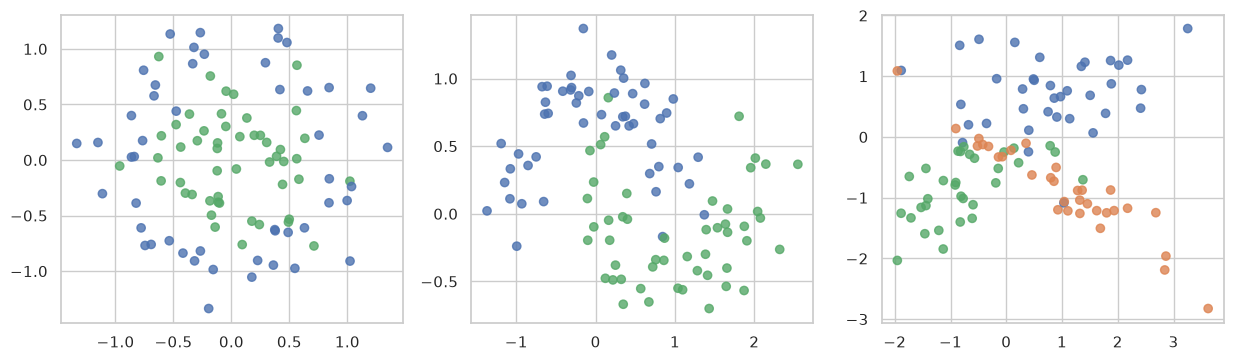

In [4]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

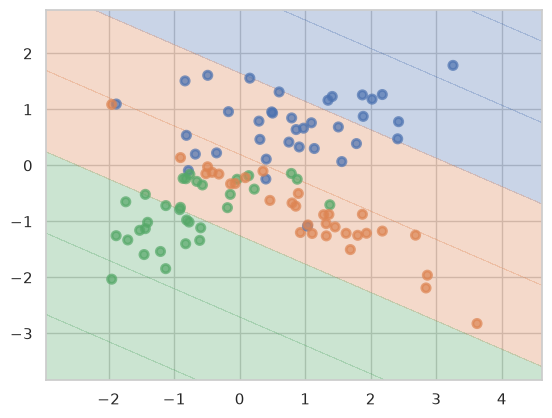

In [6]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y)

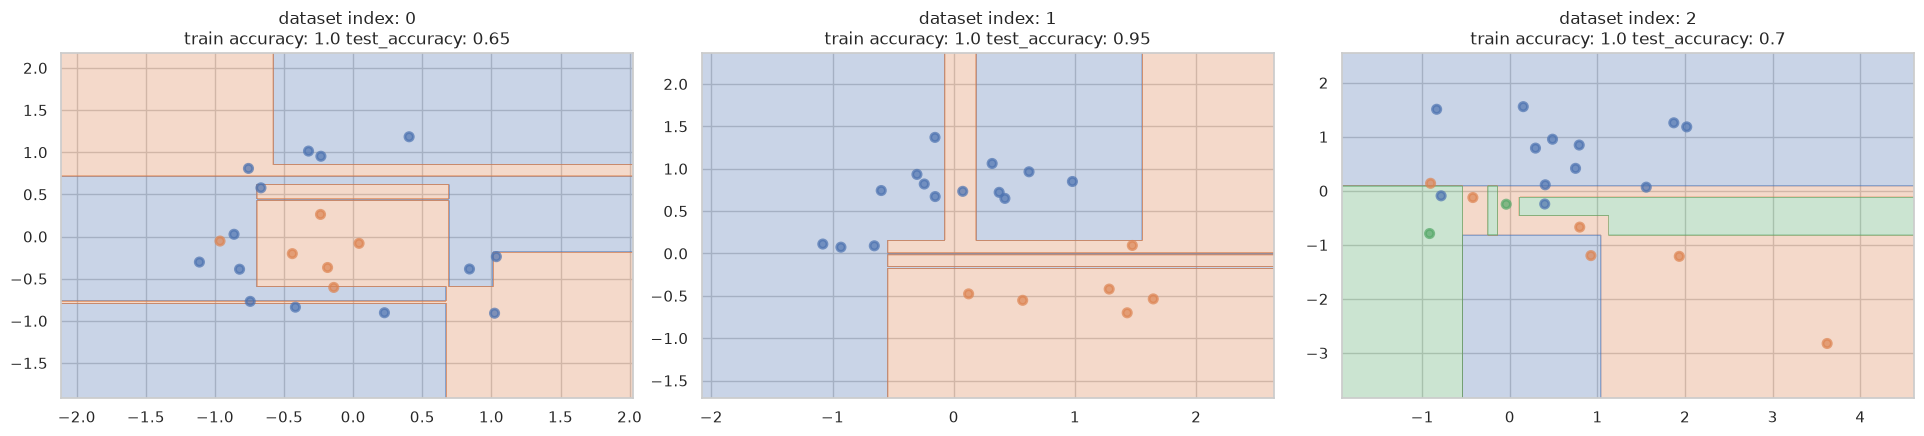

[{'dataset index': 0, 'train accuracy': 1.0, 'test accuracy': 0.65},
 {'dataset index': 1, 'train accuracy': 1.0, 'test accuracy': 0.95},
 {'dataset index': 2, 'train accuracy': 1.0, 'test accuracy': 0.7}]

In [7]:
from sklearn.metrics import accuracy_score

splits = [train_test_split(X, y, test_size=0.2, random_state=42) for X, y in datasets]
accuracies = []

plt.figure(figsize=(20, 5))

for i, split in enumerate(splits):
    X_train, X_test, y_train, y_test = split

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    test_accuracy = accuracy_score(y_test, model.predict(X_test))

    accuracies.append({
        "dataset index": i,
        "train accuracy": train_accuracy,
        "test accuracy": test_accuracy
    })

    plt.subplot(1, 3, i + 1)
    plot_surface(model, X_test, y_test)
    plt.title(f"dataset index: {i}\n" f"train accuracy: {train_accuracy} test_accuracy: {test_accuracy}")

plt.show()

accuracies

__Ответ:__ для 1 и 3 датасета видно сильное переобучение деревьев (1 на трейне и 0.65 b 0.7 на тесте, соответственно), для 2 датасета переобучение выражено заметно слабее (1 на трейне и 0.95 на тесте)

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

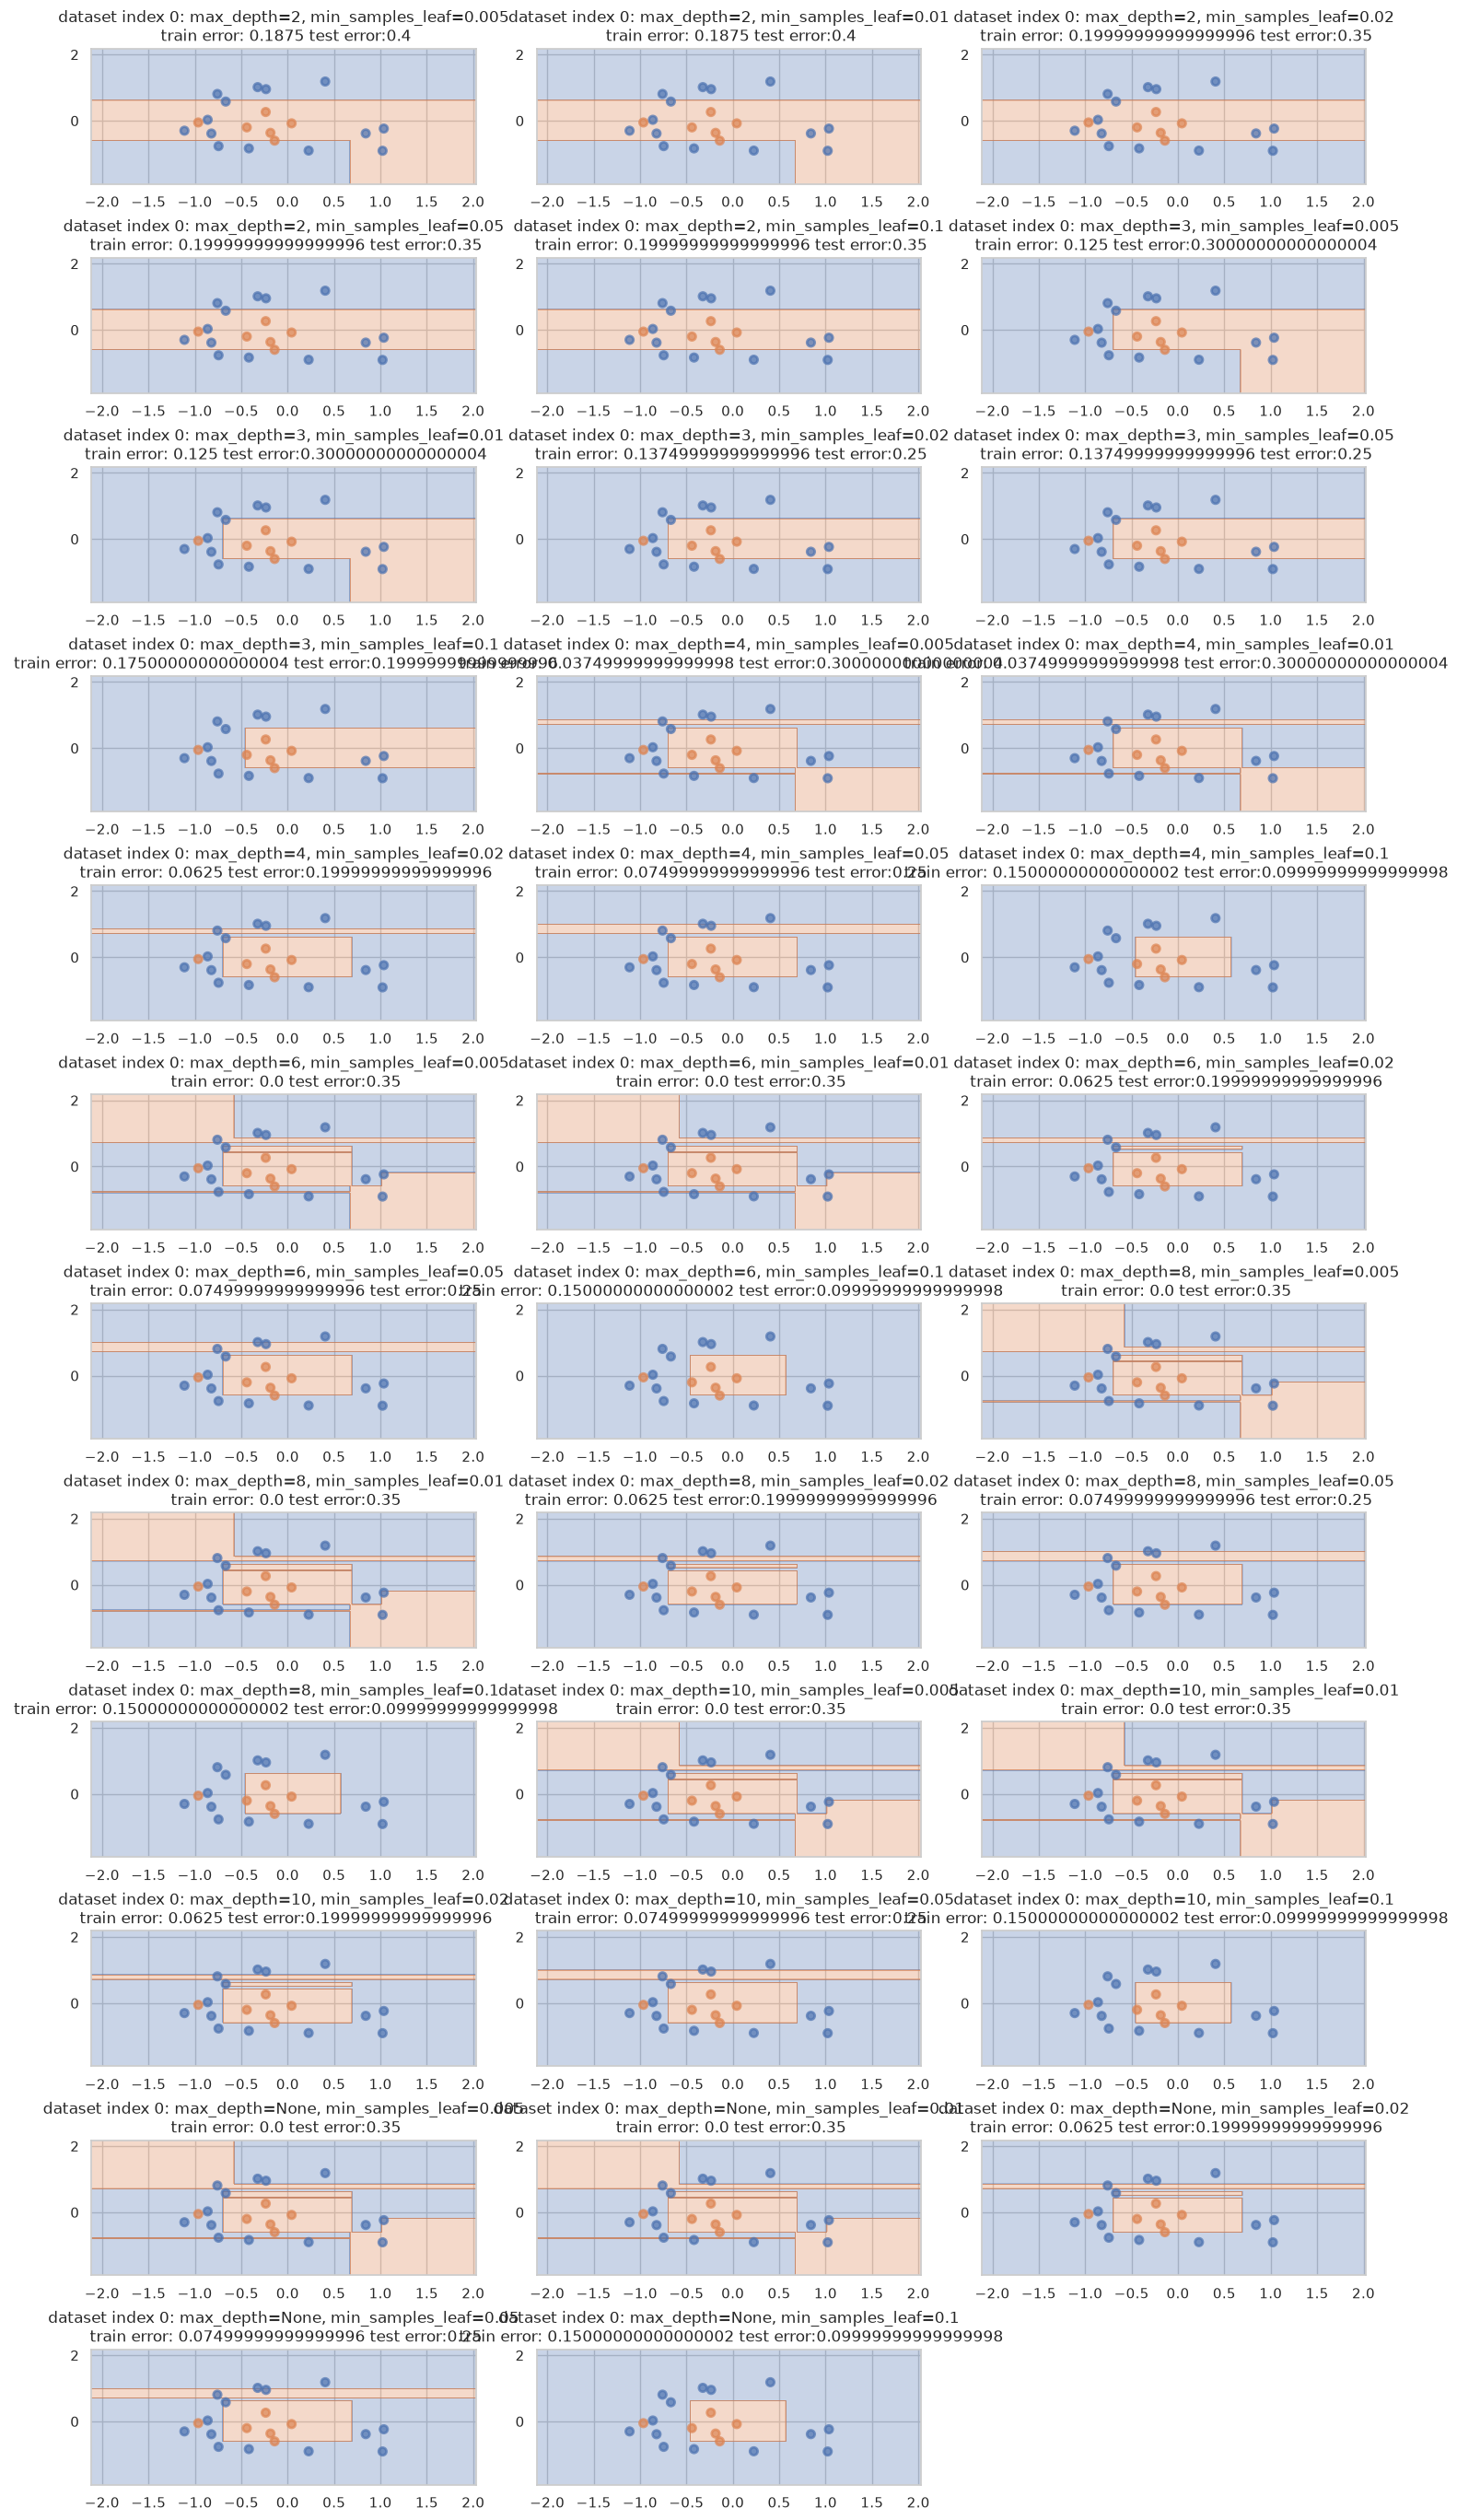

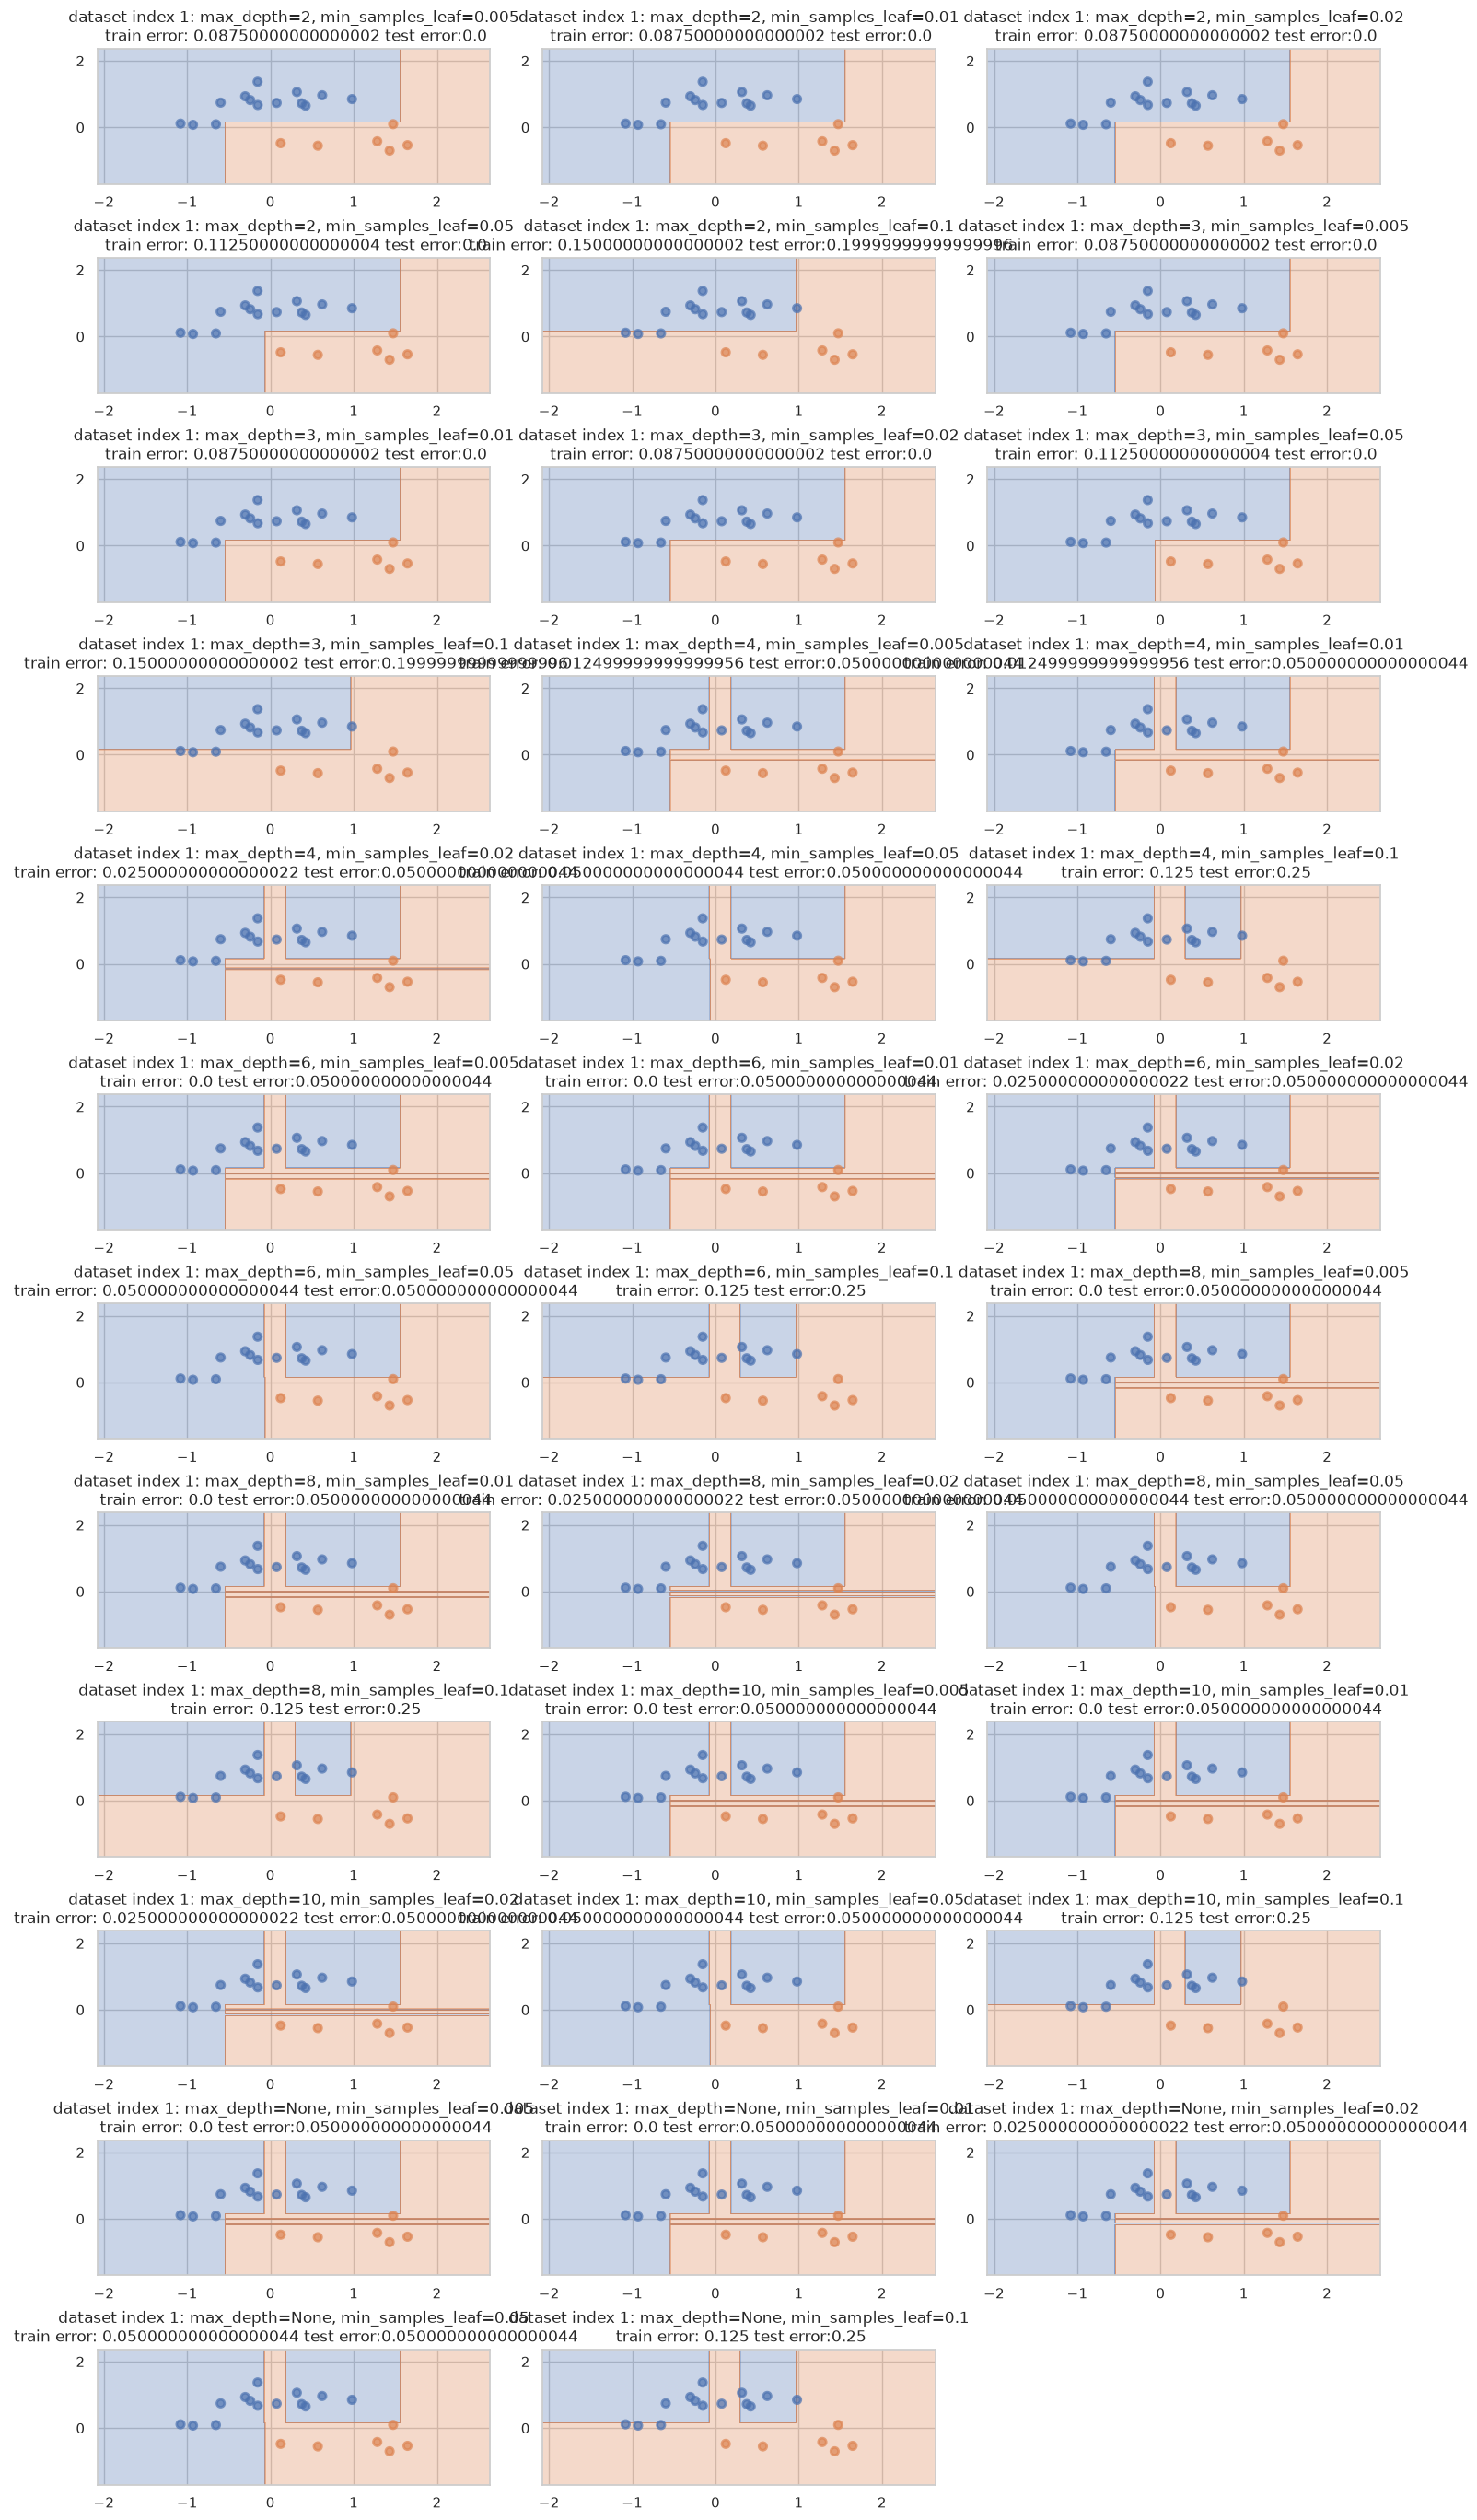

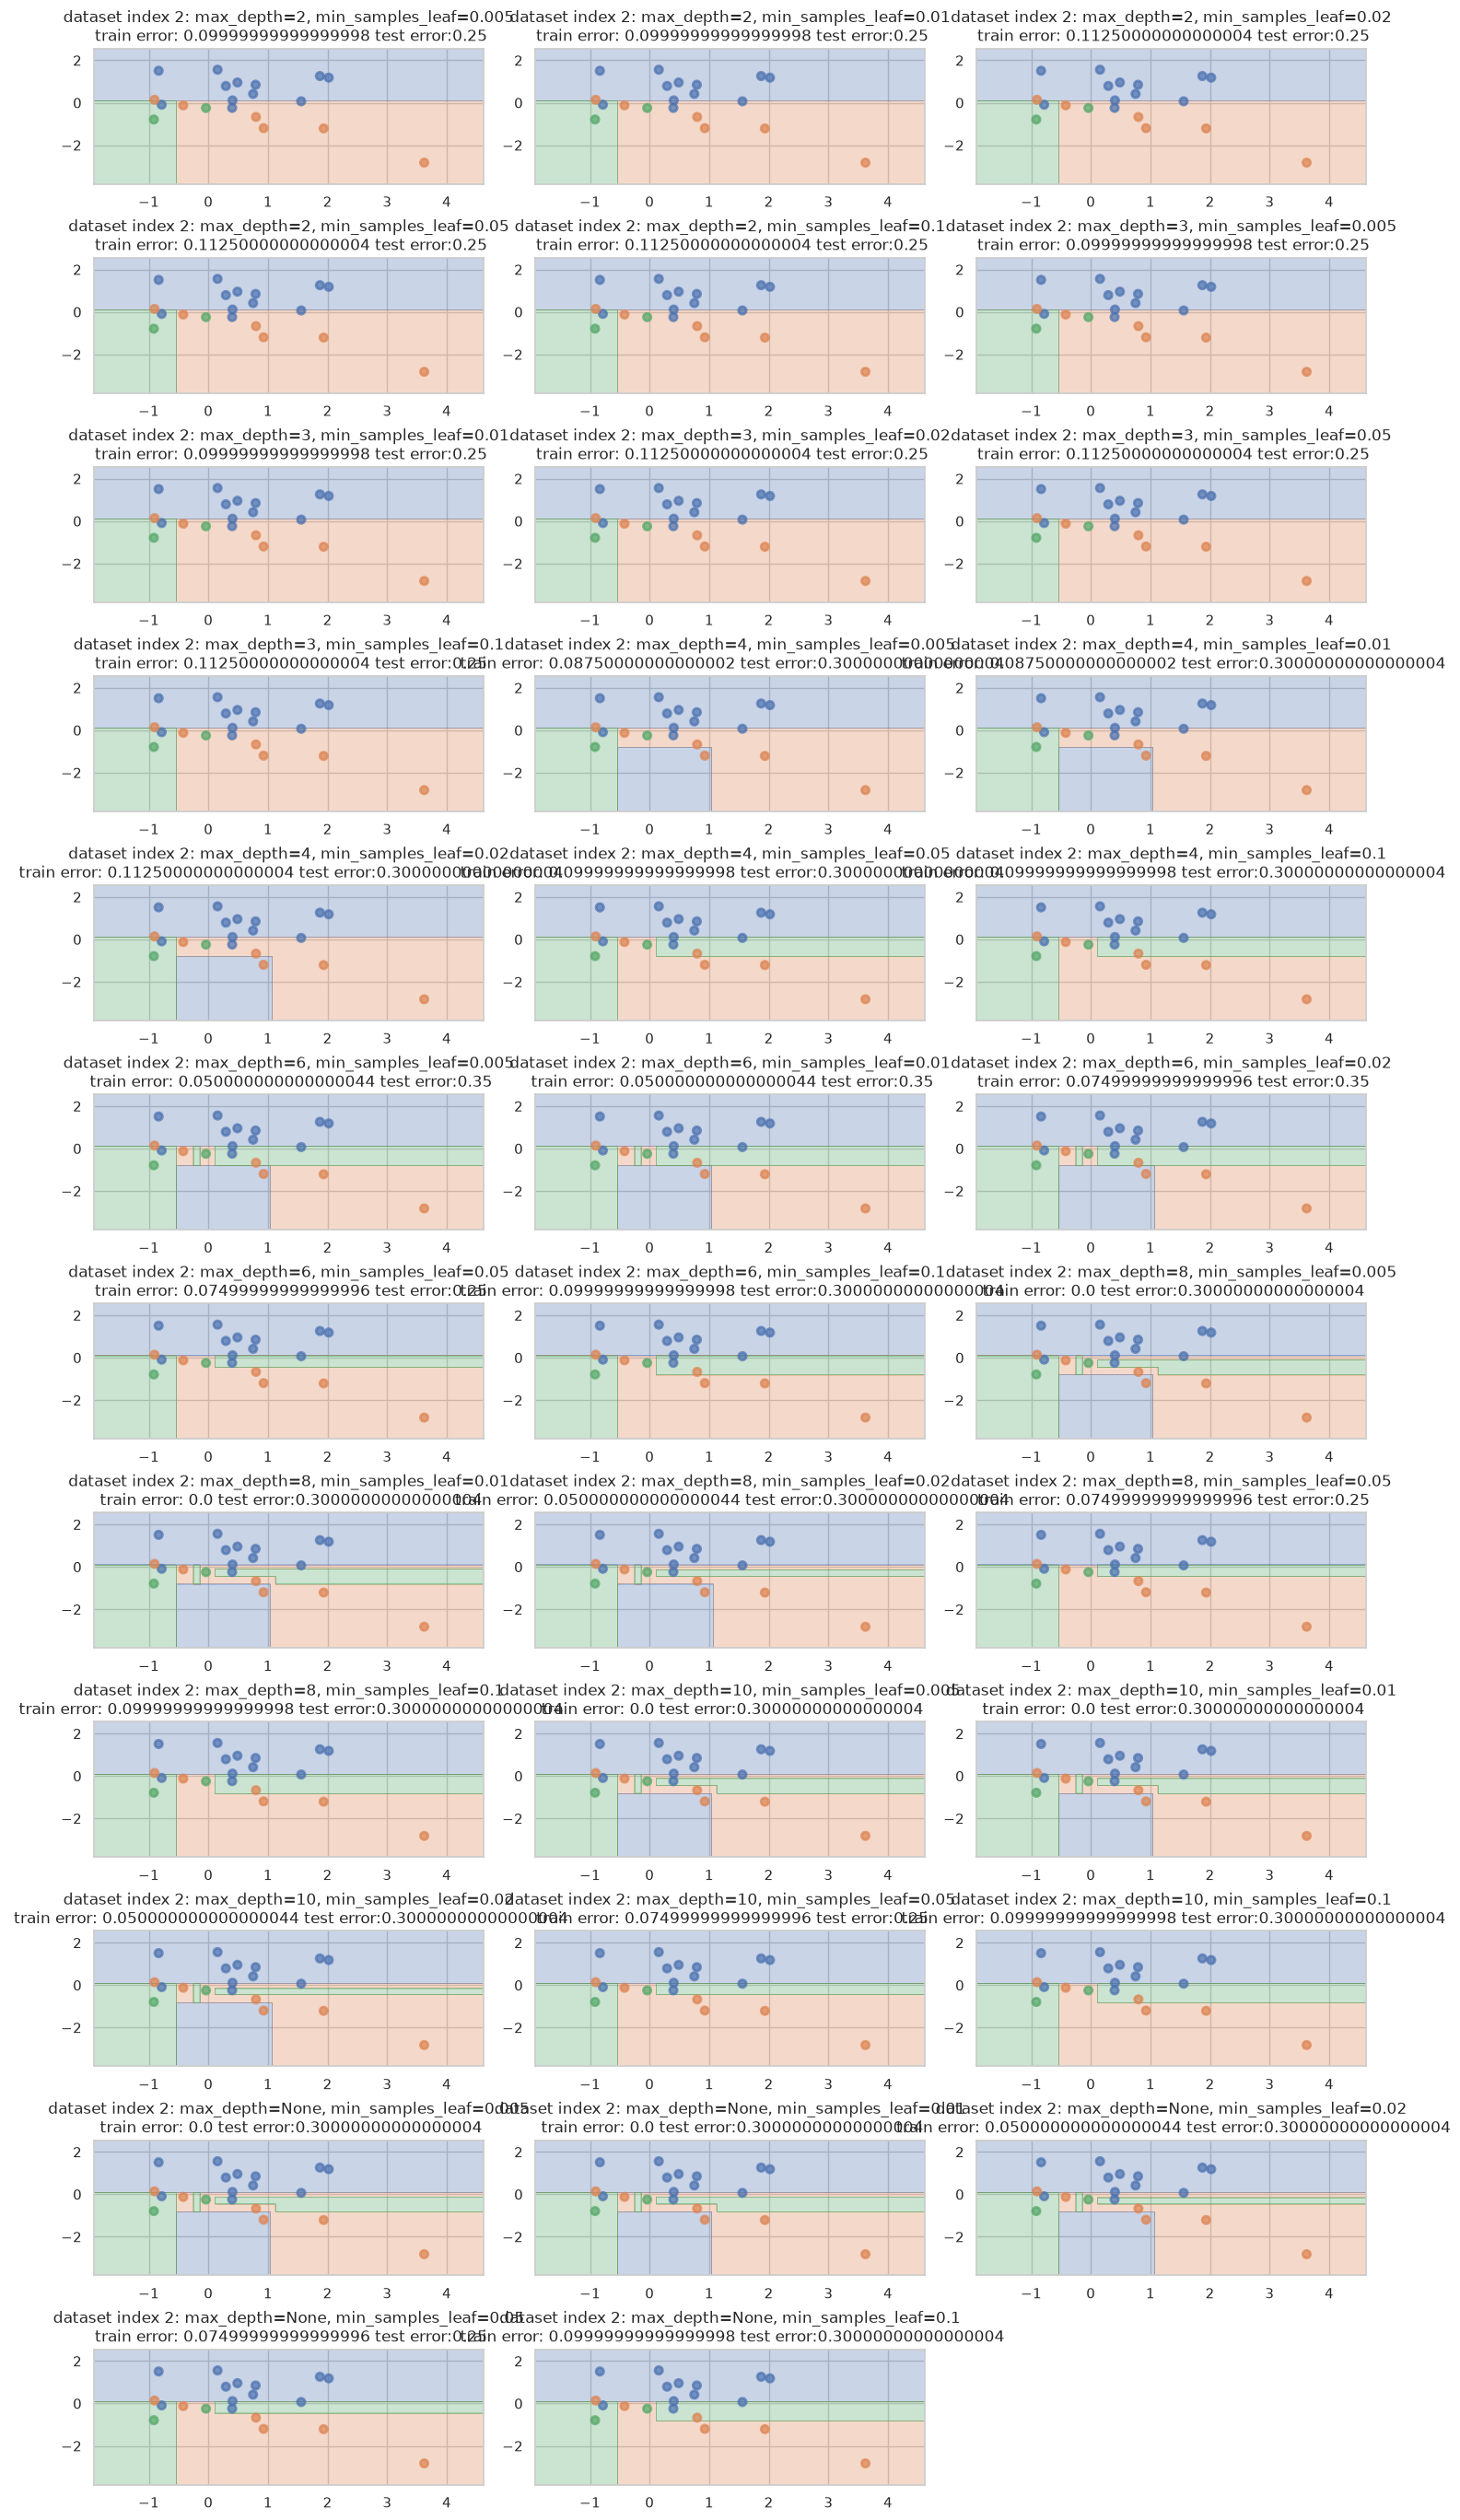

[{'dataset index': 0,
  'max_depth': 2,
  'min_samples_leaf': 0.005,
  'train error': 0.1875,
  'test error': 0.4},
 {'dataset index': 0,
  'max_depth': 2,
  'min_samples_leaf': 0.01,
  'train error': 0.1875,
  'test error': 0.4},
 {'dataset index': 0,
  'max_depth': 2,
  'min_samples_leaf': 0.02,
  'train error': 0.19999999999999996,
  'test error': 0.35},
 {'dataset index': 0,
  'max_depth': 2,
  'min_samples_leaf': 0.05,
  'train error': 0.19999999999999996,
  'test error': 0.35},
 {'dataset index': 0,
  'max_depth': 2,
  'min_samples_leaf': 0.1,
  'train error': 0.19999999999999996,
  'test error': 0.35},
 {'dataset index': 0,
  'max_depth': 3,
  'min_samples_leaf': 0.005,
  'train error': 0.125,
  'test error': 0.30000000000000004},
 {'dataset index': 0,
  'max_depth': 3,
  'min_samples_leaf': 0.01,
  'train error': 0.125,
  'test error': 0.30000000000000004},
 {'dataset index': 0,
  'max_depth': 3,
  'min_samples_leaf': 0.02,
  'train error': 0.13749999999999996,
  'test error': 

In [8]:
from sklearn.model_selection import ParameterGrid

grid = list(ParameterGrid({
    "max_depth": [2, 3, 4, 6, 8, 10, None],
    "min_samples_leaf": [0.005, 0.01, 0.02, 0.05, 0.1] 
}))

errors = []

for dataset_i, split in enumerate(splits):
    X_train, X_test, y_train, y_test = split

    plt.figure(figsize=(15, 28))

    for i, params in enumerate(grid):
        model = DecisionTreeClassifier(**params, random_state=42)
        model.fit(X_train, y_train)

        train_error = 1 - model.score(X_train, y_train)
        test_error = 1 - model.score(X_test, y_test)
        
        errors.append({
            "dataset index": dataset_i,
            **params,
            "train error": train_error,
            "test error": test_error
        })

        plt.subplot(12, 3, i + 1)
        plot_surface(model, X_test, y_test)
        plt.title(
            f"dataset index {dataset_i}: max_depth={params['max_depth']}, min_samples_leaf={params['min_samples_leaf']}\n train error: {train_error} test error:{test_error}"
        )

plt.show()

errors


__Ответ:__ для 1 датасета маленькая глубина приводит к недообучению (заметна ошибка на тесте 0.35-0.4 на max_depth=2), а большая с маленькими листьями к переобучению (заметна ошибка на тесте 0.35 при min_samples_leaf<=0.01 и max_depth>=6). Оптимальные параметры позволяют снизить ошибку на тесте до 0.1 (min_samples_leaf=0.1, max_depth=4). Для 2 датасета глубины 2-3 и min_samples_leaf<=0.05 достаточно для ошибки на тесте 0. Усложнение дерева не помогает, а большие min_samples_leaf ухудшают качество. Для 3 датасета глубокие деревья (особенно при max_depth>=8) переобучаются, но ограничение глубины до 2-3 или 6+ при min_samples_leaf=0.05 позволяет добиться оптимальной ошибки на тесте 0.25. Регуляризация упрощает разделяющую поверхность и уменьшает переобучение, но слишком строгие ограничения вызывают недообучение. Влияние параметров зависит от конкретного датасета и их нужно подбирать индивидуально, так как одни параметры улучшающие результат на одном датасете могут вызывать недообучение на другом, например.

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

In [9]:
from pathlib import Path

path = Path("datasets") / "students.csv"

df = pd.read_csv(path)
df

,STG,SCG,STR,LPR,PEG,UNS
0,0.00,0.00,0.00,0.00,0.00,0
1,0.08,0.08,0.10,0.24,0.90,1
2,0.06,0.06,0.05,0.25,0.33,0
3,0.10,0.10,0.15,0.65,0.30,1
4,0.08,0.08,0.08,0.98,0.24,0
...,...,...,...,...,...,...
253,0.61,0.78,0.69,0.92,0.58,1
254,0.78,0.61,0.71,0.19,0.60,1
255,0.54,0.82,0.71,0.29,0.77,1
256,0.50,0.75,0.81,0.61,0.26,1


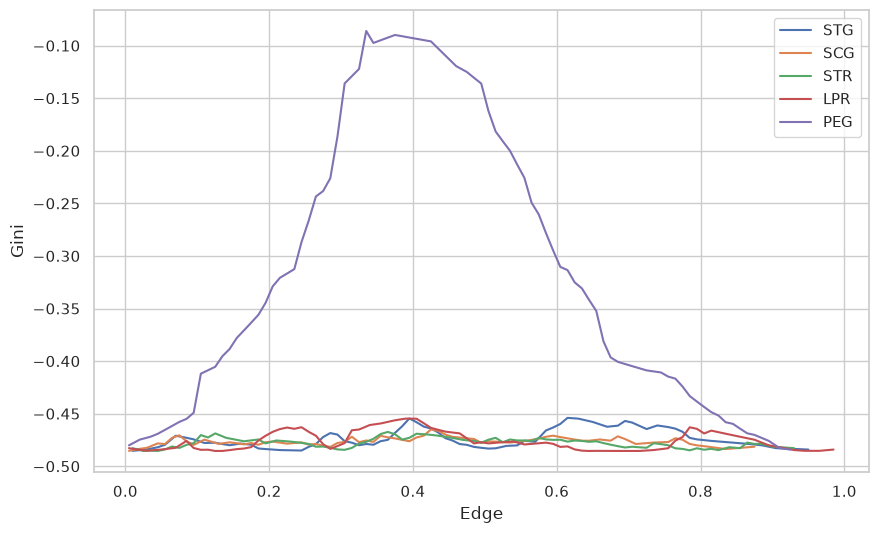

In [10]:
import hw2code

X = df.iloc[:, :-1]
y = df.iloc[:, -1].to_numpy()

splits = []

plt.figure(figsize=(10, 6))

for feature in X.columns:
    thresholds, gini, threshold_best, gini_best = hw2code.find_best_split(X[feature].to_numpy(), y)

    plt.plot(thresholds, gini, label=feature)

    splits.append({
        "feature": feature,
        "threshold best": threshold_best,
        "gini best": gini_best
    })

plt.xlabel("Edge")
plt.ylabel("Gini")
plt.legend()
plt.show()

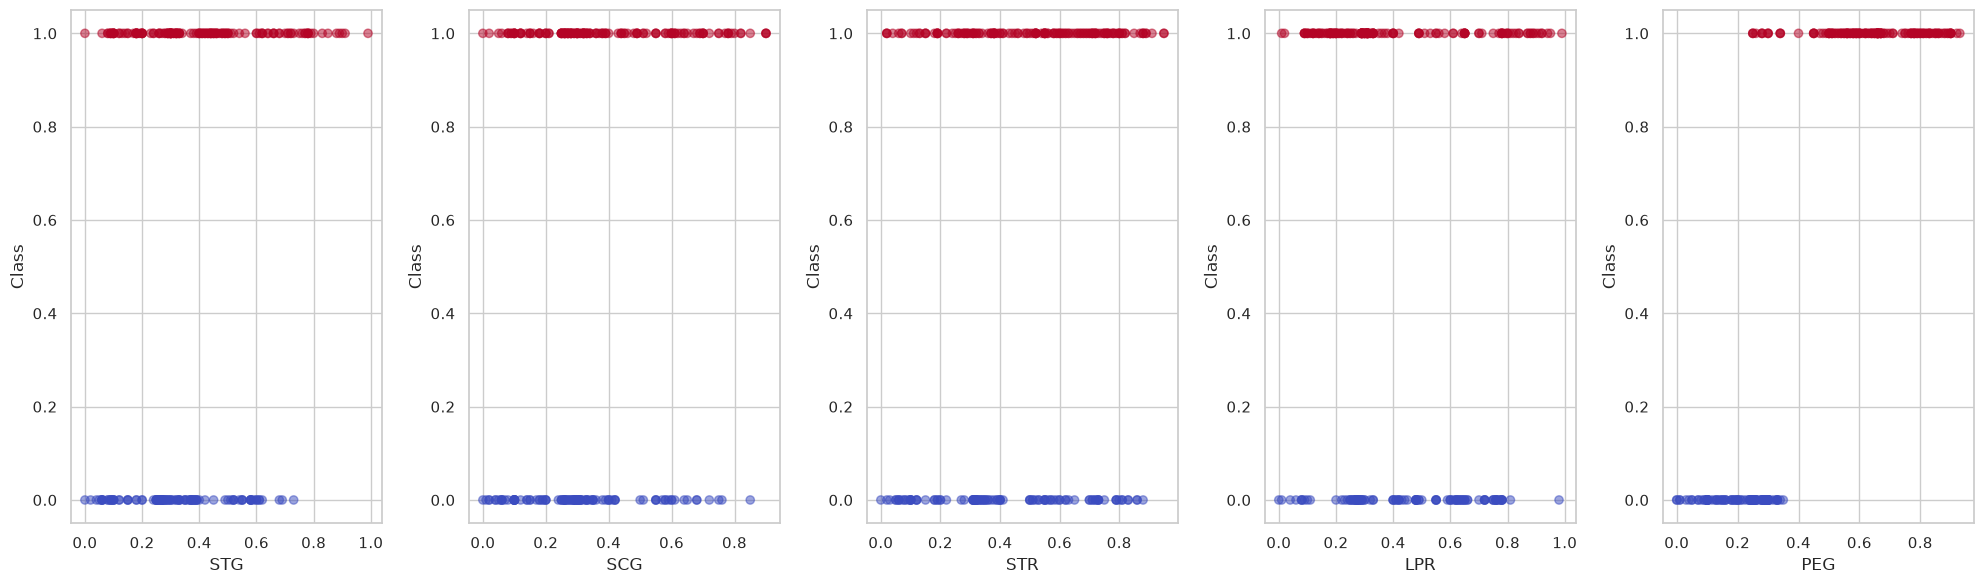

In [11]:
from matplotlib.pyplot import scatter

fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, feature in zip(axes, X.columns):
    ax.scatter(X[feature], y, c=y, cmap='coolwarm', alpha=0.5)
    ax.set_xlabel(feature)
    ax.set_ylabel("Class")

plt.tight_layout()
plt.show()

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:** производить деление нужно по признаку PEG, этот результат согласуется с визуальной оценкой scatter-графиков (примерно при PEG<=0.34 преобладает класс 0, а при PEG>=0.34 преобладает класс 1). Для "хороших" признаков кривая имеет выраженный пик (максимум) около нуля, так как нам нужно делить выборку на чистые по классам группы объектов. А для "плохих" признаков кривая будет более пологой или плоской что ли, пик (максимум) будет значительно ниже нуля, так как изменение порога плохо улучшает разделение классов по группам.

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [12]:
from sklearn.preprocessing import LabelEncoder

path = Path("datasets") / "agaricus-lepiota.data"

df = pd.read_csv(path, header=None)
df


,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [13]:
df_encoded = df.apply(lambda col: LabelEncoder().fit_transform(col))

X = df_encoded.iloc[:, 1:].to_numpy()
y = df_encoded.iloc[:, 0].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

model = hw2code.DecisionTree(feature_types=["categorical"] * X.shape[1])
model.fit(X_train, y_train)

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

print(f"Train accuracy: {accuracy_score(y_train, train_predictions)}\nTest accuracy: {accuracy_score(y_test, test_predictions)}")
print(f"Tree depth: {hw2code.DecisionTree._depth(model._tree)}")

Train accuracy: 1.0
Test accuracy: 1.0
Tree depth: 8


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

In [14]:
path = Path("datasets") / "tic-tac-toe-endgame.csv"

df = pd.read_csv(path)
df

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10
0,x,x,x,x,o,o,x,o,o,positive
1,x,x,x,x,o,o,o,x,o,positive
2,x,x,x,x,o,o,o,o,x,positive
3,x,x,x,x,o,o,o,b,b,positive
4,x,x,x,x,o,o,b,o,b,positive
...,...,...,...,...,...,...,...,...,...,...
953,o,x,x,x,o,o,o,x,x,negative
954,o,x,o,x,x,o,x,o,x,negative
955,o,x,o,x,o,x,x,o,x,negative
956,o,x,o,o,x,x,x,o,x,negative


In [15]:
df_encoded = df.apply(lambda col: LabelEncoder().fit_transform(col))

X = df_encoded.iloc[:, :-1].to_numpy()
y = df_encoded.iloc[:, -1].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base = hw2code.DecisionTree(feature_types=["categorical"] * X.shape[1])
base.fit(X_train, y_train)

base_train_predictions = base.predict(X_train)
base_test_predictions = base.predict(X_test)

print(f"Train accuracy: {accuracy_score(y_train, base_train_predictions)}\nTest accuracy: {accuracy_score(y_test, base_test_predictions)}")
print(f"Tree depth: {hw2code.DecisionTree._depth(base._tree)}")

Train accuracy: 1.0
Test accuracy: 0.9739583333333334
Tree depth: 11


In [16]:
params = {
    "max_depth": [1, 2, 3, 4, 6, 8, 10],
    "min_samples_leaf": [0.005, 0.01, 0.02, 0.05, 0.1],
    "min_samples_split": [0.01, 0.02, 0.04, 0.1, 0.2]
}

accuracies = []

for param, values in params.items():
    for value in values:
        model = hw2code.DecisionTree(feature_types=['categorical'] * X.shape[1], **{param: value})
        model.fit(X_train, y_train)
        
        train_accuracy = accuracy_score(y_train, model.predict(X_train))
        test_accuracy = accuracy_score(y_test, model.predict(X_test))

        accuracies.append({
            "param": param,
            "value": value,
            "train accuracy": train_accuracy,
            "test accuracy": test_accuracy,
            "depth": hw2code.DecisionTree._depth(model._tree)
        })

accuracies = pd.DataFrame(accuracies)
accuracies

,param,value,train accuracy,test accuracy,depth
0,max_depth,1.000,0.702350,0.687500,1
1,max_depth,2.000,0.710183,0.687500,2
2,max_depth,3.000,0.759791,0.729167,3
3,max_depth,4.000,0.839426,0.828125,4
4,max_depth,6.000,0.947781,0.937500,6
5,max_depth,8.000,0.986945,0.968750,8
6,max_depth,10.000,0.996084,0.973958,10
7,min_samples_leaf,0.005,0.960836,0.947917,8
8,min_samples_leaf,0.010,0.938642,0.932292,7
9,min_samples_leaf,0.020,0.928198,0.921875,6


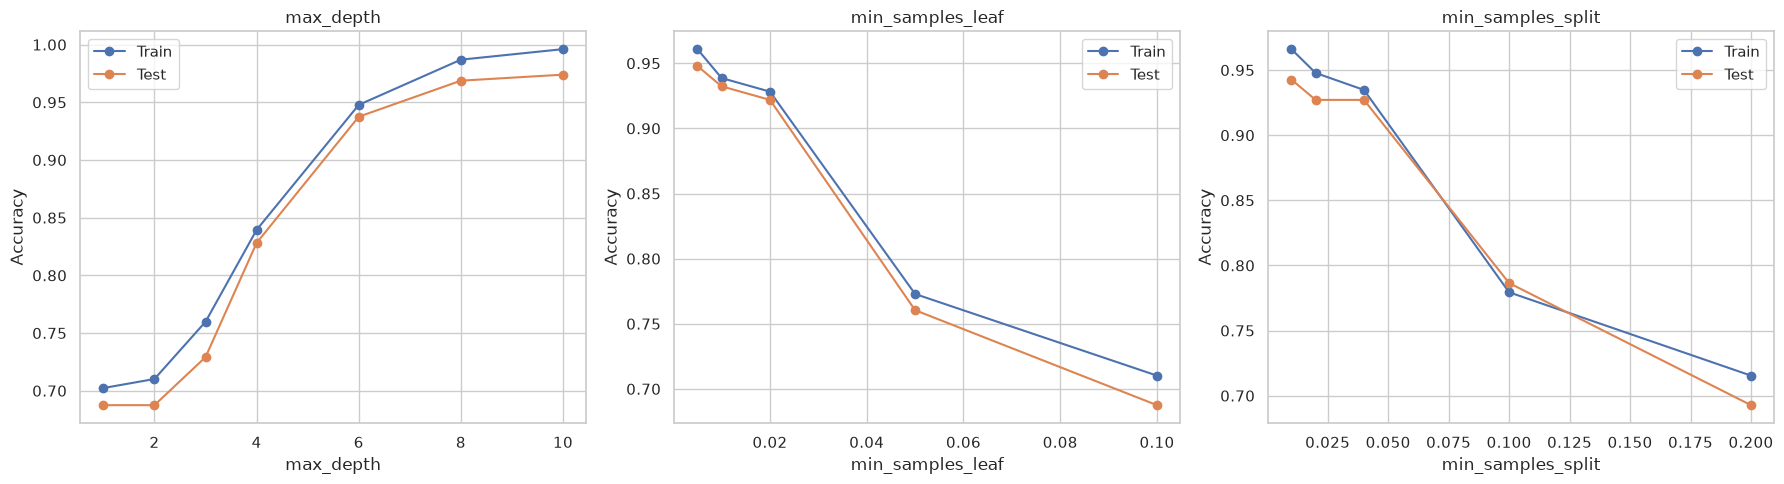

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, param in zip(axes, params):
    subset = accuracies[
        accuracies["param"] == param
    ].sort_values("value")

    ax.plot(
        subset["value"],
        subset["train accuracy"],
        marker="o",
        label="Train",
    )
    ax.plot(
        subset["value"],
        subset["test accuracy"],
        marker="o",
        label="Test",
    )

    ax.set_xlabel(param)
    ax.set_ylabel("Accuracy")
    ax.set_title(param)
    ax.legend()

plt.tight_layout()
plt.show()

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [18]:
mushrooms = pd.read_csv(Path("datasets") / "agaricus-lepiota.data", header=None)
tic_tac_toe = pd.read_csv(Path("datasets") / "tic-tac-toe-endgame.csv")
cars = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data", header=None)
nursery = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/nursery/nursery.data", header=None)

In [19]:
def encode_features(df):
    return df.apply(lambda col: LabelEncoder().fit_transform(col)).to_numpy()

X_mushrooms = encode_features(mushrooms.iloc[:, 1:])
y_mushrooms = LabelEncoder().fit_transform(mushrooms.iloc[:, 0])

X_tic_tac_toe = encode_features(tic_tac_toe.iloc[:, :-1])
y_tic_tac_toe = LabelEncoder().fit_transform(tic_tac_toe.iloc[:, -1])

X_cars = encode_features(cars.iloc[:, :-1])
y_cars = LabelEncoder().fit_transform(cars.iloc[:, -1].map({
    "unacc": 0,
    "acc": 0,
    "good": 1,
    "vgood": 1
}))

X_nursery = encode_features(nursery.iloc[:, :-1])
y_nursery = LabelEncoder().fit_transform(nursery.iloc[:, -1].map({
    "not_recom": 0,
    "recommend": 0,
    "very_recom": 1,
    "priority": 1,
    "spec_prior": 1
}))

datasets = {
    "mushrooms": [X_mushrooms, y_mushrooms],
    "tic-tac-toe": [X_tic_tac_toe, y_tic_tac_toe],
    "cars": [X_cars, y_cars],
    "nursery": [X_nursery, y_nursery]
}

In [20]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

def make_models(n_feats):
    return {
        "all_real": hw2code.DecisionTree(feature_types=["real"] * n_feats),
        "all_categorical": hw2code.DecisionTree(feature_types=['categorical'] * n_feats),
        "real_one_hot": Pipeline([
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
            ("tree", hw2code.DecisionTree(feature_types=None))
        ]),
        "sklearn": DecisionTreeClassifier(random_state=42)
    }

In [21]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_val_score

scorer = make_scorer(accuracy_score)
results = []

for dataset_name, (X_data, y_data) in datasets.items():
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    folds = list(cv.split(X_data, y_data))

    for model_name, model in make_models(X_data.shape[1]).items():
        scores = cross_val_score(
            model,
            X_data,
            y_data,
            cv=folds,
            scoring=scorer,
            error_score="raise",
            n_jobs=1,
        )

        results.append({
            "dataset": dataset_name,
            "model": model_name,
            "accuracy": scores.mean()
        })

accuracies = pd.DataFrame(results).pivot(index='dataset', columns="model", values="accuracy")
accuracies

model,all_categorical,all_real,real_one_hot,sklearn
dataset,,,,
cars,0.991894,0.991891,0.988419,0.991891
mushrooms,1.000000,1.000000,1.000000,1.000000
nursery,0.999769,0.999614,0.999769,0.999691
tic-tac-toe,0.942632,0.878947,0.938443,0.888355


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ:** Алгоритмы ранжируются по-разному на разных датасетах, т.к., например, для mushrooms я везде получил accuracy 1, для nursery я получил примерно одинаковые результаты accuracy 0.9997, но лучший результат у категориального дерева и one-hot + real, для cars я получил accuracy 0.992, но в случае one-hot + real немного хуже 0.988, для tic-tac-toe я получил более содержательную картину: лучшим оказалось категориальное дерево 0.943, а худшим оказалось вещественное дерево 0.879. Результат зависит от смысла категорий: например, в tic-tac-toe значения нельзя упорядочить как числа, они все равноценны, поэтому там категориальное дерево и one-hot + real оказались лучше. Как вариант, результат так же может меняться из-за того, какие данные попали в обучающую и тестовую выборки, на других разбиениях возможно результат поменяется. Вот это можно отнести к компоненте случайности. А для улучшения работы алгоритмов можно подбирать способ кодирования и ограничения дерева, проверяя результат на нескольких разбиениях.

Вставьте что угодно, описывающее ваши впечатления от этого задания: 52 <3